In [33]:
import numpy as np
import pandas as pd

In [34]:
data=pd.read_csv('/content/StudentPerformanceFactors.csv')

In [35]:
data.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [36]:
df = data[['Hours_Studied', 'Exam_Score']]
df.head()

,Hours_Studied,Exam_Score
0,23,67
1,19,61
2,24,74
3,29,71
4,19,70


In [64]:
df.	Hours_Studied.max()

44

In [65]:
df.	Hours_Studied.min()

1

In [66]:
df.Exam_Score.min()

55

In [67]:
df.Exam_Score.max()

101

In [37]:
df.shape

(6607, 2)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Hours_Studied  6607 non-null   int64
 1   Exam_Score     6607 non-null   int64
dtypes: int64(2)
memory usage: 103.4 KB


In [39]:
df.isnull().sum()

,0
Hours_Studied,0
Exam_Score,0


In [40]:
# Verify that no duplicate combinations remain

print("Original Dataset:", df.shape)

print(
    "Exact Duplicate Rows:",
    df.duplicated(
        subset=["Hours_Studied", "Exam_Score"]
    ).sum()
)

print(
    "Unique Combinations:",
    df.drop_duplicates(
        subset=["Hours_Studied", "Exam_Score"]
    ).shape
)

Original Dataset: (6607, 2)
Exact Duplicate Rows: 6072
Unique Combinations: (535, 2)


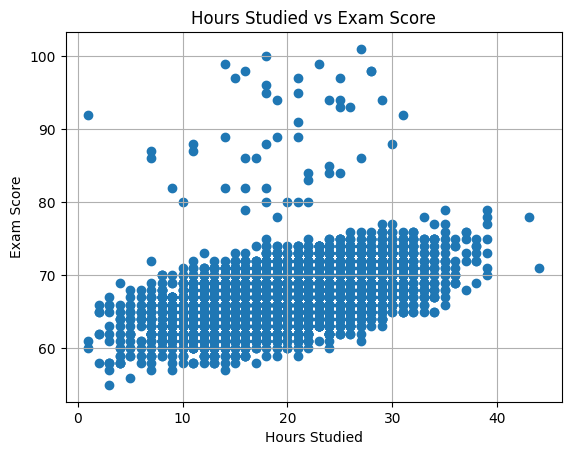

In [41]:
# Import Matplotlib for creating the scatter plot
import matplotlib.pyplot as plt

# Plot Hours_Studied on the X-axis and Exam_Score on the Y-axis
plt.scatter(df["Hours_Studied"], df["Exam_Score"])

# Set the X-axis label
plt.xlabel("Hours Studied")

# Set the Y-axis label
plt.ylabel("Exam Score")

# Set the title of the scatter plot
plt.title("Hours Studied vs Exam Score")

# Display grid lines on the plot
plt.grid(True)

# Display the scatter plot
plt.show()

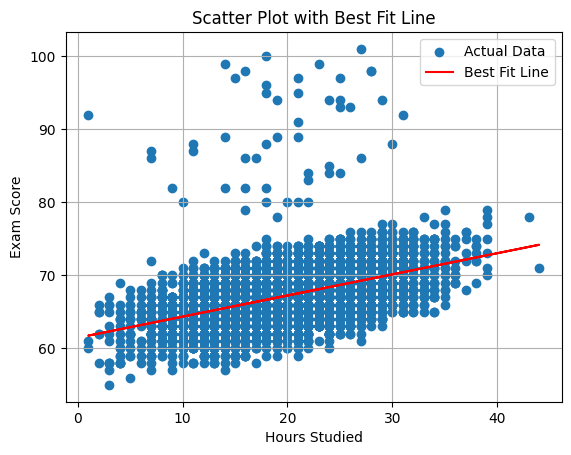

In [42]:
# Import the required libraries
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Select the input feature and target variable
X = df[["Hours_Studied"]]
y = df["Exam_Score"]

# Create a Linear Regression model
model = LinearRegression()

# Train the model using the dataset
model.fit(X, y)

# Predict Exam_Score values for the best fit line
y_pred = model.predict(X)

# Plot the actual data points
plt.scatter(X["Hours_Studied"], y, label="Actual Data")

# Plot the best fit line
plt.plot(X["Hours_Studied"], y_pred, color="red", label="Best Fit Line")

# Add labels and title
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Scatter Plot with Best Fit Line")

# Display the legend and grid
plt.legend()
plt.grid(True)

# Display the plot
plt.show()

In [43]:
# Import the required libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


In [44]:
# Select the input feature and target variable
X = df[["Hours_Studied"]]
y = df["Exam_Score"]

In [45]:
# Split the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [46]:
# Display the shapes of the training and testing datasets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5285, 1)
X_test: (1322, 1)
y_train: (5285,)
y_test: (1322,)


In [47]:

# Import libraries for data preparation and evaluation
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import the ten regression algorithms
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

# Select the required columns and remove missing values
data = df[["Hours_Studied", "Exam_Score"]].dropna()

# Define the input feature and target variable
X = data[["Hours_Studied"]]
y = data["Exam_Score"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define a function to calculate regression metrics
def evaluate_model(model, model_name):

    # Train the model
    model.fit(X_train, y_train)

    # Predict exam scores using the test data
    y_pred = model.predict(X_test)

    # Calculate MAE, RMSE, and R2 score
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Display the evaluation results
    print("Algorithm:", model_name)
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R² Score:", round(r2, 4))


# **1. Linear Regression**

In [48]:

# Create the Linear Regression model
model = LinearRegression()

# Train the model and calculate evaluation metrics
evaluate_model(model, "Linear Regression")


Algorithm: Linear Regression
MAE: 2.4476
RMSE: 3.2948
R² Score: 0.232


# **2.Polynomial Regression**

In [49]:

# Create a Polynomial Regression model with degree 2
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Polynomial Regression")


Algorithm: Polynomial Regression
MAE: 2.4448
RMSE: 3.2932
R² Score: 0.2328


# **3. Ridge Regression**

In [50]:

# Scale the input feature and create the Ridge model
model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Ridge Regression")


Algorithm: Ridge Regression
MAE: 2.4476
RMSE: 3.2948
R² Score: 0.232


# **4.Lasso Regression**

In [51]:

# Scale the input feature and create the Lasso model
model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=10000)
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Lasso Regression")


Algorithm: Lasso Regression
MAE: 2.452
RMSE: 3.2996
R² Score: 0.2297


# 5.**Elastic** Net Regression

In [52]:

# Scale the input feature and create the Elastic Net model
model = make_pipeline(
    StandardScaler(),
    ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Elastic Net Regression")


Algorithm: Elastic Net Regression
MAE: 2.4537
RMSE: 3.3016
R² Score: 0.2288


# **6.Decision Tree Regressor**

In [53]:

# Create the Decision Tree Regressor model
model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Decision Tree Regressor")


Algorithm: Decision Tree Regressor
MAE: 2.4755
RMSE: 3.323
R² Score: 0.2188


# 7.**Random Forest Regressor**

In [54]:

# Create the Random Forest Regressor model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Random Forest Regressor")


Algorithm: Random Forest Regressor
MAE: 2.4772
RMSE: 3.3226
R² Score: 0.219


# **8.Support Vector Regression (SVR)**

In [55]:

# Scale the input feature and create the SVR model
model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Support Vector Regression")


Algorithm: Support Vector Regression
MAE: 2.4537
RMSE: 3.302
R² Score: 0.2286


# **9.K-Neighbors Regressor (KNN)**

In [56]:

# Scale the input feature and create the KNN model
model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5)
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "K-Neighbors Regressor")


Algorithm: K-Neighbors Regressor
MAE: 2.6206
RMSE: 3.4712
R² Score: 0.1475


# **10.Gradient Boosting Regressor**

In [57]:

# Create the Gradient Boosting Regressor model
model = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model and calculate evaluation metrics
evaluate_model(model, "Gradient Boosting Regressor")


Algorithm: Gradient Boosting Regressor
MAE: 2.4767
RMSE: 3.3226
R² Score: 0.219


In [58]:
# if 2 or more algo (MAE,RMSE,R² Score value) are same then use this process
# Print the metrics with higher precision
print(f"Linear Regression MAE:  {mae_linear:.10f}")
print(f"Ridge Regression MAE:   {mae_ridge:.10f}")

print(f"Linear Regression RMSE: {rmse_linear:.10f}")
print(f"Ridge Regression RMSE:  {rmse_ridge:.10f}")

print(f"Linear Regression R2:   {r2_linear:.10f}")
print(f"Ridge Regression R2:    {r2_ridge:.10f}")

Linear Regression MAE:  2.4475687453
Ridge Regression MAE:   2.4475794013
Linear Regression RMSE: 3.2948325130
Ridge Regression RMSE:  3.2948431944
Linear Regression R2:   0.2319868675
Ridge Regression R2:    0.2319818879


In [59]:
print('Linear Regression is best algo on this data set')

Linear Regression is best algo on this data set


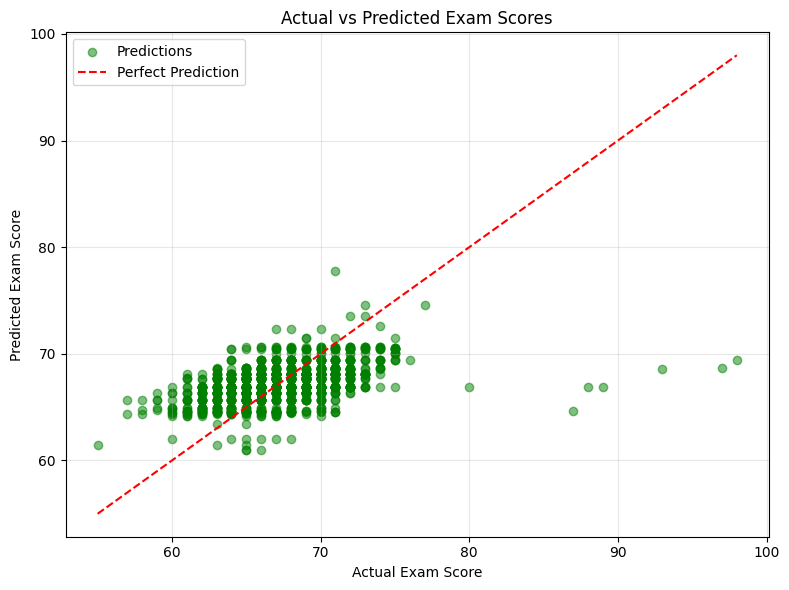

In [60]:
# Import the required libraries
import matplotlib.pyplot as plt
import pandas as pd

# Train the Linear Regression model
model.fit(X_train, y_train)

# Predict exam scores using the test dataset
y_pred = model.predict(X_test)

# Create a scatter plot of actual and predicted exam scores
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color="green", label="Predictions")

# Draw a reference line for perfect predictions
# Points on this line have Actual Score = Predicted Score
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

# Add the graph title and axis labels
plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")

# Display the legend and grid
plt.legend()
plt.grid(alpha=0.3)

# Display the final graph
plt.tight_layout()
plt.show()

In [75]:
# Import pandas to create input data in DataFrame format
import pandas as pd

# Ask the user to enter the number of study hours
hours = float(input("Enter Hours Studied: "))

# Create a DataFrame using the same feature name used during training
new_data = pd.DataFrame({
    "Hours_Studied": [hours]
})

# Predict the exam score using the trained Linear Regression model
predicted_score = model.predict(new_data)

# Display the predicted exam score
print("\n--- Exam Score Prediction ---")
print(f"Hours Studied: {hours}")
print(f"Predicted Exam Score: {predicted_score[0]:.2f}")

Enter Hours Studied: 0.1

--- Exam Score Prediction ---
Hours Studied: 0.1
Predicted Exam Score: 70.87


In [71]:
# Import pandas to create a comparison table
import pandas as pd

# Compare actual scores with predicted scores
comparison = pd.DataFrame({
    "Actual_Score": y_test,
    "Predicted_Score": y_pred
})

# Calculate the prediction error
comparison["Error"] = (
    comparison["Actual_Score"] - comparison["Predicted_Score"]
)

# Display the first 10 predictions
print(comparison.head(10))

      Actual_Score  Predicted_Score     Error
743             65        66.909672 -1.909672
5551            65        67.660593 -2.660593
3442            71        67.740794  3.259206
6571            64        64.890720 -0.890720
4204            66        67.740794 -1.740794
2516            66        67.740794 -1.740794
4047            72        73.511371 -1.511371
1706            66        68.152783 -2.152783
1075            70        66.316838  3.683162
233             70        66.316838  3.683162
